# XGBoost: binary and multiclass

Gradient-boosted trees: many small decision trees built one after another, each one correcting the mistakes of the ones before it. On tabular data like this, XGBoost often beats both Random Forest and neural networks, so it is a strong second baseline.


## 1. Imports

In [2]:
# %pip install xgboost matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import (
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)

print("xgboost", xgb.__version__)

xgboost 3.4.1


## 2. Config

`n_estimators` is only an upper limit. Early stopping ends training once the validation loss has not improved for `EARLY_STOPPING_ROUNDS` rounds, and the best round is used.

In [3]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

XGB_PARAMS = dict(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=8,
    min_child_weight=1,
    subsample=0.8,            # each tree sees 80% of the rows
    colsample_bytree=0.8,     # and 80% of the features
    reg_lambda=1.0,
    tree_method="hist",       # fast histogram-based training
    n_jobs=-1,
    random_state=SEED,
)
EARLY_STOPPING_ROUNDS = 30

## 3. Load the processed data

In [4]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"], data["X_val"]
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_classes = len(class_names)

# XGBoost has no class_weight option, so the class weights become per-row sample weights
cw_bin = np.array([meta["class_weight_binary"][str(k)] if str(k) in meta["class_weight_binary"]
                   else meta["class_weight_binary"][k] for k in (0, 1)])
cw_multi = np.array([meta["class_weight_multi"][str(i)] for i in range(n_classes)])
w_bin_train = cw_bin[yb_train]
w_multi_train = cw_multi[ym_train]

print("X_train:", X_train.shape, "  X_val:", X_val.shape, "  classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)   classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Binary XGBoost (normal vs attack)

The validation set is used for early stopping, so the validation scores are slightly optimistic. Mention this in your report.

In [5]:
xgb_bin = xgb.XGBClassifier(
    objective="binary:logistic", eval_metric="logloss",
    early_stopping_rounds=EARLY_STOPPING_ROUNDS, **XGB_PARAMS)

t0 = time.time()
xgb_bin.fit(X_train, yb_train, sample_weight=w_bin_train,
            eval_set=[(X_train, yb_train), (X_val, yb_val)], verbose=False)
print(f"trained {xgb_bin.best_iteration + 1} rounds (best) in {time.time() - t0:.1f}s")

proba_bin = xgb_bin.predict_proba(X_val)[:, 1]
pred_bin = (proba_bin >= 0.5).astype(int)

print(classification_report(yb_val, pred_bin, target_names=["Normal", "Attack"], digits=4))
tn, fp, fn, tp = confusion_matrix(yb_val, pred_bin).ravel()
fpr = fp / (fp + tn)
print(f"ROC-AUC:              {roc_auc_score(yb_val, proba_bin):.4f}")
print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
print(f"False negative rate:  {fn / (fn + tp):.4f}  ({fn} attacks missed)")

trained 469 rounds (best) in 9.7s
              precision    recall  f1-score   support

      Normal     0.9072    0.9633    0.9344     11200
      Attack     0.9823    0.9537    0.9678     23869

    accuracy                         0.9568     35069
   macro avg     0.9447    0.9585    0.9511     35069
weighted avg     0.9583    0.9568    0.9571     35069

ROC-AUC:              0.9951
False positive rate:  0.0367  (411 normal flows flagged as attacks)
False negative rate:  0.0463  (1104 attacks missed)


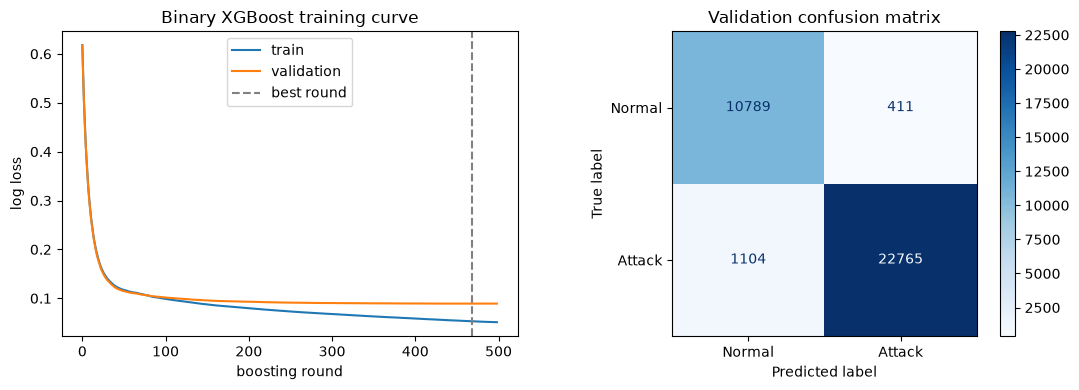

In [6]:
res = xgb_bin.evals_result()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(res["validation_0"]["logloss"], label="train")
axes[0].plot(res["validation_1"]["logloss"], label="validation")
axes[0].axvline(xgb_bin.best_iteration, color="grey", linestyle="--", label="best round")
axes[0].set_xlabel("boosting round"); axes[0].set_ylabel("log loss")
axes[0].set_title("Binary XGBoost training curve"); axes[0].legend()

ConfusionMatrixDisplay.from_predictions(
    yb_val, pred_bin, display_labels=["Normal", "Attack"], cmap="Blues",
    ax=axes[1], values_format="d")
axes[1].set_title("Validation confusion matrix")
plt.tight_layout()
plt.show()

### Optional: tune the alert threshold

In [7]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (proba_bin >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(yb_val, p, labels=[0, 1]).ravel()
    rows.append({"threshold": t,
                 "precision": precision_score(yb_val, p, zero_division=0),
                 "recall": recall_score(yb_val, p),
                 "f1": f1_score(yb_val, p),
                 "false_pos_rate": fp_ / (fp_ + tn_)})
pd.DataFrame(rows).round(4)

,threshold,precision,recall,f1,false_pos_rate
0,0.3,0.9698,0.9769,0.9733,0.0648
1,0.4,0.9774,0.9654,0.9714,0.0475
2,0.5,0.9823,0.9537,0.9678,0.0367
3,0.6,0.9868,0.9423,0.9641,0.0268
4,0.7,0.9907,0.9287,0.9587,0.0187
5,0.8,0.9940,0.9134,0.9520,0.0117
6,0.9,0.9964,0.8885,0.9394,0.0068


## 5. Multiclass XGBoost

In [8]:
xgb_multi = xgb.XGBClassifier(
    objective="multi:softprob", num_class=n_classes, eval_metric="mlogloss",
    early_stopping_rounds=EARLY_STOPPING_ROUNDS, **XGB_PARAMS)

t0 = time.time()
xgb_multi.fit(X_train, ym_train, sample_weight=w_multi_train,
              eval_set=[(X_train, ym_train), (X_val, ym_val)], verbose=False)
print(f"trained {xgb_multi.best_iteration + 1} rounds (best) in {time.time() - t0:.1f}s")

pred_multi = xgb_multi.predict(X_val)
labels = list(range(n_classes))

print(classification_report(ym_val, pred_multi, labels=labels, target_names=class_names,
                            digits=4, zero_division=0))
print("macro F1:    %.4f" % f1_score(ym_val, pred_multi, average="macro"))
print("weighted F1: %.4f" % f1_score(ym_val, pred_multi, average="weighted"))

trained 85 rounds (best) in 11.8s
                precision    recall  f1-score   support

        Normal     0.9916    0.8629    0.9228     11200
           DoS     0.2542    0.4823    0.3330      2453
Reconnaissance     0.8142    0.8080    0.8111      2099
       Fuzzers     0.6874    0.8708    0.7683      3637
      Exploits     0.8455    0.5015    0.6296      6678
       Generic     0.9980    0.9836    0.9907      8000
         Other     0.2035    0.4331    0.2769      1002

      accuracy                         0.7803     35069
     macro avg     0.6849    0.7060    0.6761     35069
  weighted avg     0.8490    0.7803    0.8000     35069

macro F1:    0.6761
weighted F1: 0.8000


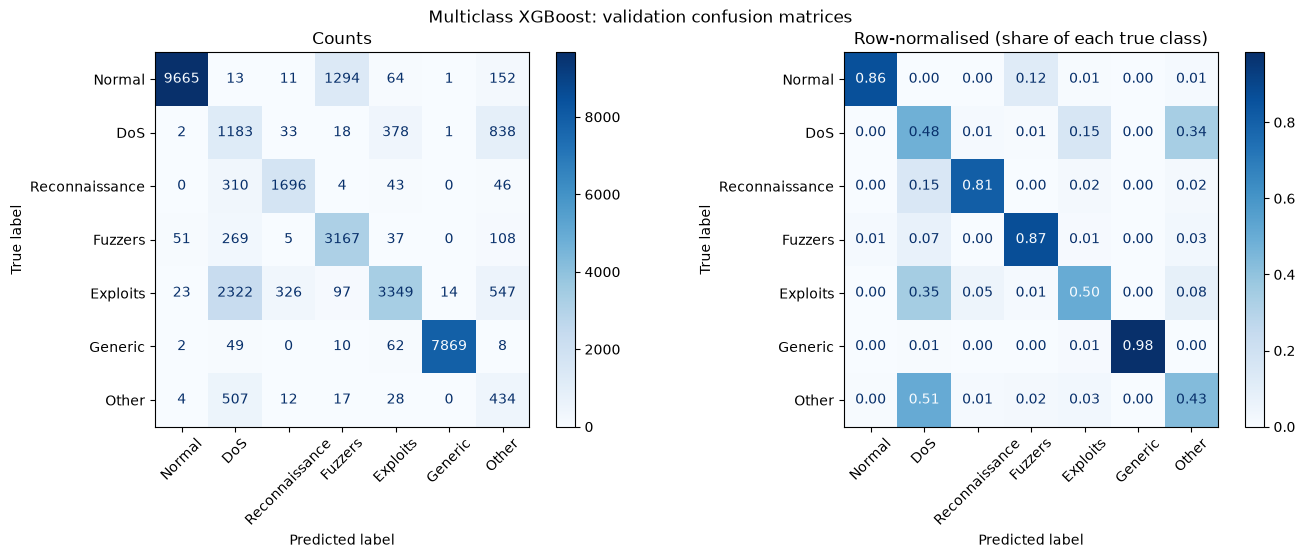

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(
    ym_val, pred_multi, labels=labels, display_labels=class_names,
    normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
axes[1].set_title("Row-normalised (share of each true class)")
plt.suptitle("Multiclass XGBoost: validation confusion matrices")
plt.tight_layout()
plt.show()

## 6. Detection rate by attack type

Was the flow flagged as an attack at all, and was it given the right type? For the Normal row, the first column is the false alarm rate.

In [10]:
flagged = pred_multi != 0          # class 0 is Normal
rows = []
for i, name in enumerate(class_names):
    m = ym_val == i
    rows.append({"true class": name, "flows": int(m.sum()),
                 "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                 "correct type (%)": round(100 * (pred_multi[m] == i).mean(), 2)})
pd.DataFrame(rows)

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,13.71,86.29
1,DoS,2453,99.92,48.23
2,Reconnaissance,2099,100.00,80.80
3,Fuzzers,3637,98.60,87.08
4,Exploits,6678,99.66,50.15
5,Generic,8000,99.98,98.36
6,Other,1002,99.60,43.31


## 7. Feature importance

Importance here is the average gain: how much each feature improves the trees' splits when it is used.

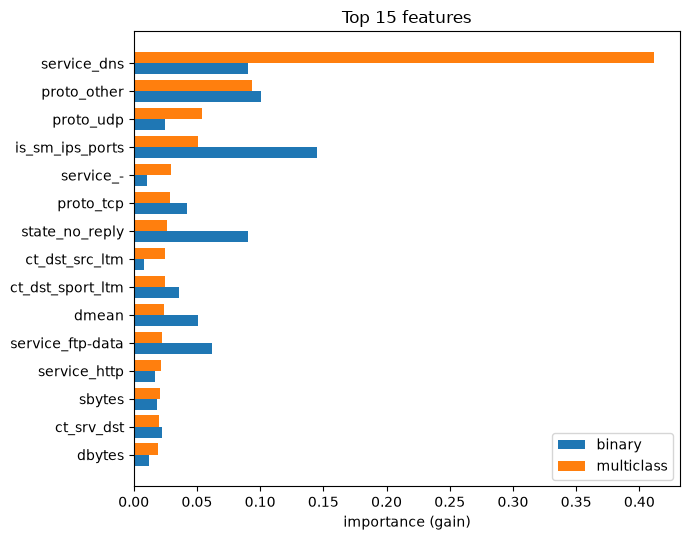

In [11]:
imp = (pd.DataFrame({
            "feature": feature_names,
            "binary": xgb_bin.feature_importances_,
            "multiclass": xgb_multi.feature_importances_})
       .sort_values("multiclass", ascending=False))

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.5))
y = np.arange(len(top))
ax.barh(y - 0.2, top["binary"], height=0.4, label="binary")
ax.barh(y + 0.2, top["multiclass"], height=0.4, label="multiclass")
ax.set_yticks(y); ax.set_yticklabels(top["feature"])
ax.set_xlabel("importance (gain)"); ax.set_title("Top 15 features"); ax.legend()
plt.tight_layout()
plt.show()

## 8. Compare all models

Loads the summaries saved by the other notebooks, if they exist.

In [12]:
xgb_summary = pd.DataFrame([
    {"model": "XGBoost binary",
     "precision": precision_score(yb_val, pred_bin),
     "recall": recall_score(yb_val, pred_bin),
     "f1": f1_score(yb_val, pred_bin),
     "false_pos_rate": fpr},
    {"model": "XGBoost multiclass (macro)",
     "precision": precision_score(ym_val, pred_multi, average="macro", zero_division=0),
     "recall": recall_score(ym_val, pred_multi, average="macro", zero_division=0),
     "f1": f1_score(ym_val, pred_multi, average="macro"),
     "false_pos_rate": np.nan},
])

parts = []
for fname in ["rf_validation_summary.csv", "mlp_validation_summary.csv",
              "ae_validation_summary.csv"]:
    p = Path(MODEL_DIR) / fname
    if p.exists():
        parts.append(pd.read_csv(p))
    else:
        print(f"{fname} not found, skipping")
parts.append(xgb_summary)
pd.concat(parts, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate
0,RF binary,0.9757,0.9610,0.9683,0.0511
1,RF multiclass (macro),0.6378,0.6286,0.6239,NaN
2,MLP binary,0.9800,0.9279,0.9532,0.0404
3,MLP multiclass (macro),0.7120,0.7350,0.6985,NaN
4,Autoencoder binary,0.9666,0.6791,0.7977,0.0500
5,XGBoost binary,0.9823,0.9537,0.9678,0.0367
6,XGBoost multiclass (macro),0.6849,0.7060,0.6761,NaN


## 9. Save the models

In [13]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

xgb_bin.save_model(mdir / "xgb_binary.json")
xgb_multi.save_model(mdir / "xgb_multiclass.json")
imp.to_csv(mdir / "xgb_feature_importance.csv", index=False)
xgb_summary.to_csv(mdir / "xgb_validation_summary.csv", index=False)

for f in sorted(mdir.glob("xgb_*")):
    print(f"{f.name:30s} {f.stat().st_size / 1e6:8.2f} MB")

xgb_binary.json                    6.28 MB
xgb_feature_importance.csv         0.00 MB
xgb_multiclass.json                9.45 MB
xgb_validation_summary.csv         0.00 MB


## 10. Using the saved model later (live pipeline)

```python
model = xgb.XGBClassifier()
model.load_model("models/xgb_binary.json")

X = transform_with_artifacts(build_model_frame(flows_df))   # from the preprocessing notebook
alert = model.predict_proba(X)[:, 1] >= 0.5
```